# Superstore Sales Analysis: Final Data Analytics Project
**AICTE | IBM SkillsBuild Data Analytics with AI Internship, Week 6**

Author: Gajanan Raje

Steps in this notebook: load data, inspect, clean, EDA, correlation, outliers, charts, insights.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the dataset
The data comes as 3 related tables: **Orders** (transactions), **Products** and **Customers**.

In [2]:
orders    = pd.read_csv("Orders_fixed.csv", encoding="utf-8", encoding_errors="replace")
products  = pd.read_csv("Products.csv",     encoding="utf-8", encoding_errors="replace")
customers = pd.read_csv("Customers.csv",    encoding="utf-8", encoding_errors="replace")

for name, df in [("Orders", orders), ("Products", products), ("Customers", customers)]:
    print(f"{name:10s} -> {df.shape[0]:>6,} rows x {df.shape[1]} columns")
orders.head()

Orders     ->  9,994 rows x 16 columns
Products   ->  1,862 rows x 4 columns
Customers  ->    793 rows x 3 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country,City,State,Postal Code,Region,Product ID,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,United States,Los Angeles,California,90036,West,OFF-LA-10000240,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,22.3680,2,0.20,2.5164


## 2. Data inspection: columns and data types

In [3]:
for name, df in [("Orders", orders), ("Products", products), ("Customers", customers)]:
    print(f"--- {name} ---")
    print(df.dtypes.to_string())
    print()

--- Orders ---
Row ID           int64
Order ID           str
Order Date         str
Ship Date          str
Ship Mode          str
Customer ID        str
Country            str
City               str
State              str
Postal Code      int64
Region             str
Product ID         str
Sales          float64
Quantity         int64
Discount       float64
Profit         float64

--- Products ---
Product ID      str
Category        str
Sub-Category    str
Product Name    str

--- Customers ---
Customer ID      str
Customer Name    str
Segment          str



## 3. Missing values and duplicates

In [4]:
for name, df in [("Orders", orders), ("Products", products), ("Customers", customers)]:
    print(f"{name:10s} missing cells: {int(df.isna().sum().sum()):>3} | duplicate rows: {df.duplicated().sum():>3}")

print("Duplicate Product IDs :", products["Product ID"].duplicated().sum())
print("Duplicate Customer IDs:", customers["Customer ID"].duplicated().sum())
print("Duplicate Row IDs     :", orders["Row ID"].duplicated().sum())

# referential integrity: every order must have a matching product and customer
print("Orders without matching product :", (~orders["Product ID"].isin(products["Product ID"])).sum())
print("Orders without matching customer:", (~orders["Customer ID"].isin(customers["Customer ID"])).sum())

Orders     missing cells:   0 | duplicate rows:   0
Products   missing cells:   0 | duplicate rows:   0
Customers  missing cells:   0 | duplicate rows:   0
Duplicate Product IDs : 0
Duplicate Customer IDs: 0
Duplicate Row IDs     : 0
Orders without matching product : 0
Orders without matching customer: 0


**Result:** no missing values, no duplicate rows and every order links to a product and a customer.
Still, a few fixes are needed: dates are stored as text, some customer names have corrupted characters, and the tables must be joined.

## 4. Data cleaning and preparation

In [5]:
# 4.1 Dates: text -> datetime
orders["Order Date"] = pd.to_datetime(orders["Order Date"])
orders["Ship Date"]  = pd.to_datetime(orders["Ship Date"])

# 4.2 Corrupted characters in customer names (e.g. "Franzï¿½sisch") -> remove the garbled characters
pattern = "ï¿½|\ufffd"
bad = customers["Customer Name"].str.contains(pattern, regex=True).sum()
customers["Customer Name"] = customers["Customer Name"].str.replace(pattern, "", regex=True)
print("Customer names with corrupted characters fixed:", bad)

# 4.3 Trim whitespace in all text columns
for df in (orders, products, customers):
    for c in df.select_dtypes(include=["object", "string"]).columns:
        df[c] = df[c].str.strip()

# 4.4 Sanity checks on values
assert (orders["Ship Date"] >= orders["Order Date"]).all(), "ship date before order date"
print("Negative sales   :", (orders["Sales"] < 0).sum())
print("Quantity <= 0    :", (orders["Quantity"] <= 0).sum())
print("Discount outside 0-1:", ((orders["Discount"] < 0) | (orders["Discount"] > 1)).sum())

Customer names with corrupted characters fixed: 6
Negative sales   : 0
Quantity <= 0    : 0
Discount outside 0-1: 0


In [6]:
# 4.5 Join the 3 tables into one analysis table
df = (orders
      .merge(products,  on="Product ID",  how="left", validate="m:1")
      .merge(customers, on="Customer ID", how="left", validate="m:1"))

# 4.6 Derived columns
df["Year"]          = df["Order Date"].dt.year
df["Month"]         = df["Order Date"].dt.month
df["Month Name"]    = df["Order Date"].dt.strftime("%b")
df["YearMonth"]     = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Delivery Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100
df["Loss Making"]   = df["Profit"] < 0

print("Final shape:", df.shape)
print("Missing after join:", int(df.isna().sum().sum()))
df.to_csv("Superstore_cleaned.csv", index=False)
df.head()

Final shape: (9994, 28)
Missing after join: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country,City,State,Postal Code,Region,Product ID,Sales,Quantity,Discount,Profit,Category,Sub-Category,Product Name,Customer Name,Segment,Year,Month,Month Name,YearMonth,Delivery Days,Profit Margin %,Loss Making
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,261.9600,2,0.00,41.9136,Furniture,Bookcases,Bush Somerset Collection Bookcase,Claire Gute,Consumer,2016,11,Nov,2016-11-01,3,16.00,False
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,731.9400,3,0.00,219.5820,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",Claire Gute,Consumer,2016,11,Nov,2016-11-01,3,30.00,False
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,United States,Los Angeles,California,90036,West,OFF-LA-10000240,14.6200,2,0.00,6.8714,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,Darrin Van Huff,Corporate,2016,6,Jun,2016-06-01,4,47.00,False
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,957.5775,5,0.45,-383.0310,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,Sean O'Donnell,Consumer,2015,10,Oct,2015-10-01,7,-40.00,True
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,22.3680,2,0.20,2.5164,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,Sean O'Donnell,Consumer,2015,10,Oct,2015-10-01,7,11.25,False


## 5. Exploratory Data Analysis

### 5.1 Descriptive statistics

In [7]:
num_cols = ["Sales", "Quantity", "Discount", "Profit", "Profit Margin %", "Delivery Days"]
df[num_cols].describe().round(2)

,Sales,Quantity,Discount,Profit,Profit Margin %,Delivery Days
count,9994.00,9994.00,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66,12.03,3.96
std,623.25,2.23,0.21,234.26,46.68,1.75
min,0.44,1.00,0.00,-6599.98,-275.00,0.00
25%,17.28,2.00,0.00,1.73,7.50,3.00
50%,54.49,3.00,0.20,8.67,27.00,4.00
75%,209.94,5.00,0.20,29.36,36.25,5.00
max,22638.48,14.00,0.80,8399.98,50.00,7.00


In [8]:
total_sales  = df["Sales"].sum()
total_profit = df["Profit"].sum()
print(f"Total Sales    : {total_sales:,.0f}")
print(f"Total Profit   : {total_profit:,.0f}")
print(f"Profit Margin  : {total_profit/total_sales:.2%}")
print(f"Total Orders   : {df['Order ID'].nunique():,}")
print(f"Customers      : {df['Customer ID'].nunique():,}")
print(f"Products       : {df['Product ID'].nunique():,}")
print(f"Period         : {df['Order Date'].min().date()} to {df['Order Date'].max().date()}")
print(f"Loss-making order lines: {df['Loss Making'].mean():.1%}")

Total Sales    : 2,297,201
Total Profit   : 286,397
Profit Margin  : 12.47%
Total Orders   : 5,009
Customers      : 793
Products       : 1,862
Period         : 2014-01-03 to 2017-12-30
Loss-making order lines: 18.7%


### 5.2 Correlation analysis

               Sales  Quantity  Discount  Profit  Delivery Days
Sales           1.00      0.20     -0.03    0.48          -0.01
Quantity        0.20      1.00      0.01    0.07           0.02
Discount       -0.03      0.01      1.00   -0.22           0.00
Profit          0.48      0.07     -0.22    1.00          -0.00
Delivery Days  -0.01      0.02      0.00   -0.00           1.00


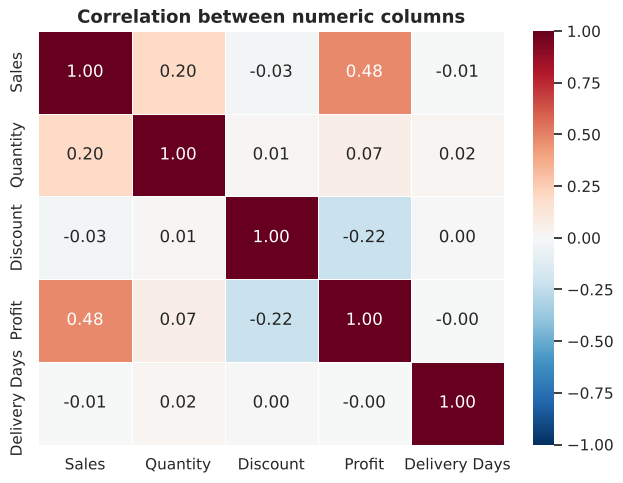

In [9]:
corr = df[["Sales", "Quantity", "Discount", "Profit", "Delivery Days"]].corr()
print(corr.round(2))

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5)
plt.title("Correlation between numeric columns")
save("05_correlation_heatmap")
plt.show()

### 5.3 Outlier detection (IQR method)

In [10]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).sum(), low, high

for col in ["Sales", "Profit", "Quantity", "Discount"]:
    n, low, high = iqr_outliers(df[col])
    print(f"{col:9s}: {n:>5,} outliers ({n/len(df):.1%})   valid range {low:,.1f} to {high:,.1f}")

Sales    : 1,167 outliers (11.7%)   valid range -271.7 to 498.9
Profit   : 1,881 outliers (18.8%)   valid range -39.7 to 70.8
Quantity :   170 outliers (1.7%)   valid range -2.5 to 9.5
Discount :   856 outliers (8.6%)   valid range -0.3 to 0.5


Top 5 largest losses:


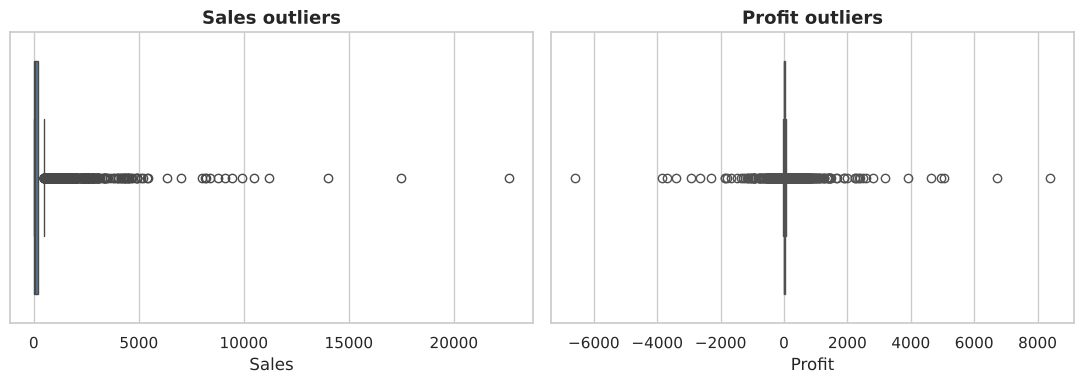

,Order ID,Product Name,Sales,Discount,Profit
7772,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,0.7,-6599.9780
683,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,7999.980,0.5,-3839.9904
9774,CA-2014-169019,GBC DocuBind P400 Electric Binding System,2177.584,0.8,-3701.8928
3011,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,2549.985,0.7,-3399.9800
4991,US-2017-122714,Ibico EPK-21 Electric Binding System,1889.990,0.8,-2929.4845


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df["Sales"],  ax=axes[0], color="#4C78A8"); axes[0].set_title("Sales outliers");  axes[0].set_xlabel("Sales")
sns.boxplot(x=df["Profit"], ax=axes[1], color="#F58518"); axes[1].set_title("Profit outliers"); axes[1].set_xlabel("Profit")
save("06_outliers_boxplot")
plt.show()

print("Top 5 largest losses:")
df.nsmallest(5, "Profit")[["Order ID", "Product Name", "Sales", "Discount", "Profit"]]

**Outlier note:** large orders and large losses are real business events (big machines, heavy discounts), not data errors, so they are **kept**.

## 6. Data visualisation (7 charts)

### Chart 1: Sales and profit by category

                    Sales    Profit  Margin %
Category                                     
Technology       836154.0  145454.9      17.4
Furniture        741999.8   18451.3       2.5
Office Supplies  719047.0  122490.8      17.0


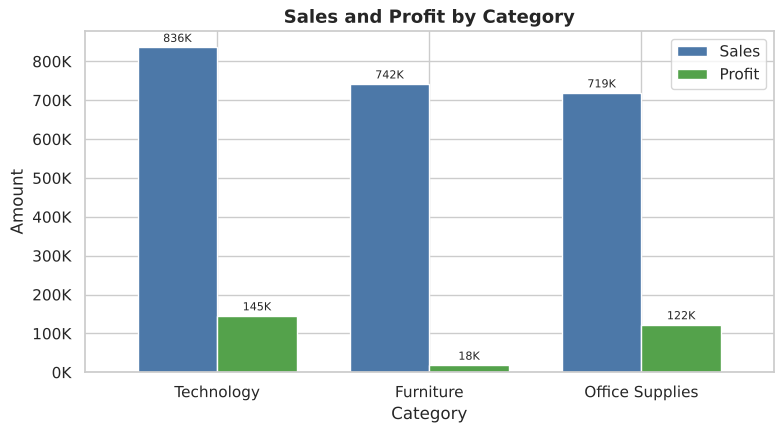

In [12]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
cat["Margin %"] = cat["Profit"] / cat["Sales"] * 100
print(cat.round(1))

ax = cat[["Sales", "Profit"]].plot(kind="bar", figsize=(8, 4.5), color=["#4C78A8", "#54A24B"], width=.75)
ax.set_title("Sales and Profit by Category")
ax.set_xlabel("Category"); ax.set_ylabel("Amount")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e3:,.0f}K")
for c in ax.containers: ax.bar_label(c, labels=[f"{v/1e3:,.0f}K" for v in c.datavalues], fontsize=8, padding=2)
plt.xticks(rotation=0)
save("01_sales_profit_by_category")
plt.show()

### Chart 2: Monthly sales trend

         Sales   Profit  Sales growth %
Year                                   
2014  484247.5  49544.0             NaN
2015  470532.5  61618.6            -2.8
2016  609205.6  81795.2            29.5
2017  733215.3  93439.3            20.4


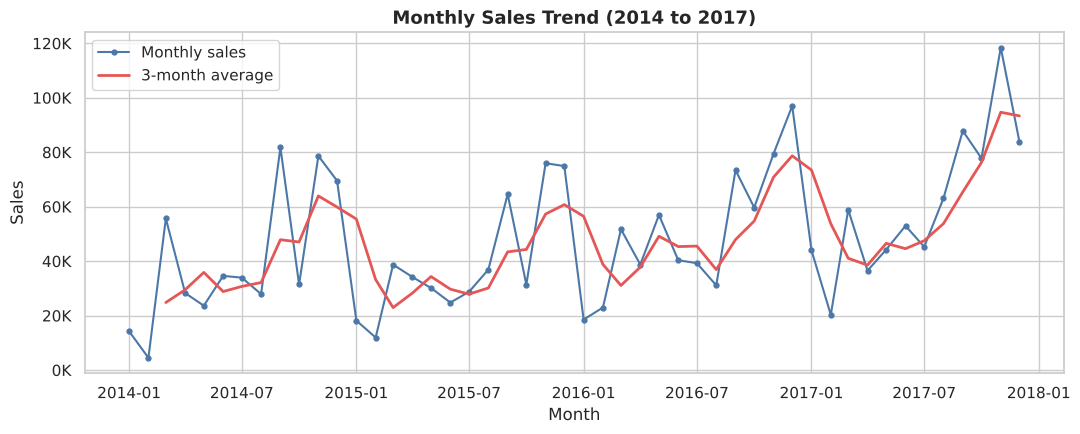

In [13]:
monthly = df.groupby("YearMonth")["Sales"].sum()
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly.values, marker="o", ms=3.5, color="#4C78A8", label="Monthly sales")
ax.plot(monthly.index, monthly.rolling(3).mean(), color="#E45756", lw=2, label="3-month average")
ax.set_title("Monthly Sales Trend (2014 to 2017)")
ax.set_xlabel("Month"); ax.set_ylabel("Sales")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e3:,.0f}K")
ax.legend()
save("02_monthly_sales_trend")
plt.show()

yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales growth %"] = yearly["Sales"].pct_change() * 100
print(yearly.round(1))

### Chart 3: Profit by region

            Sales    Profit  Margin %
Region                               
West     725457.8  108418.4      14.9
East     678781.2   91522.8      13.5
South    391721.9   46749.4      11.9
Central  501239.9   39706.4       7.9


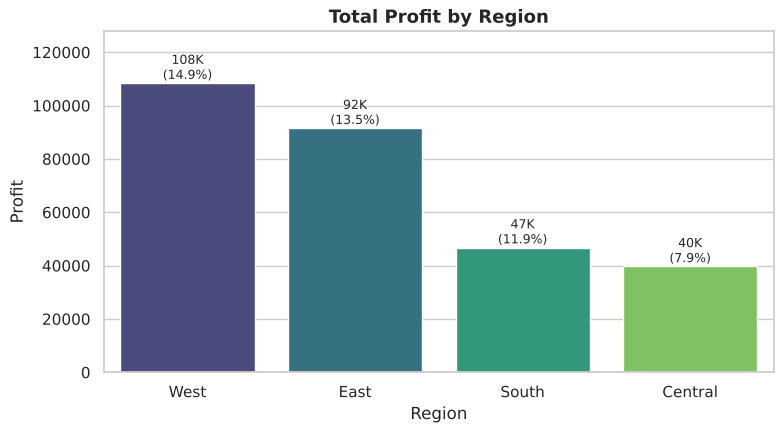

In [14]:
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
reg["Margin %"] = reg["Profit"] / reg["Sales"] * 100
reg = reg.sort_values("Profit", ascending=False)
print(reg.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=reg.index, y=reg["Profit"], palette="viridis", ax=ax)
ax.set_title("Total Profit by Region"); ax.set_xlabel("Region"); ax.set_ylabel("Profit")
for i, (p, m) in enumerate(zip(reg["Profit"], reg["Margin %"])):
    ax.text(i, p, f"{p/1e3:,.0f}K\n({m:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, reg["Profit"].max() * 1.18)
save("03_profit_by_region")
plt.show()

### Chart 4: Profit by sub-category

Sub-Category
Tables        -17725.0
Bookcases      -3473.0
Supplies       -1189.0
Fasteners        950.0
Machines        3385.0
Labels          5546.0
Art             6528.0
Envelopes       6964.0
Furnishings    13059.0
Appliances     18138.0
Storage        21279.0
Chairs         26590.0
Binders        30222.0
Paper          34054.0
Accessories    41937.0
Phones         44516.0
Copiers        55618.0


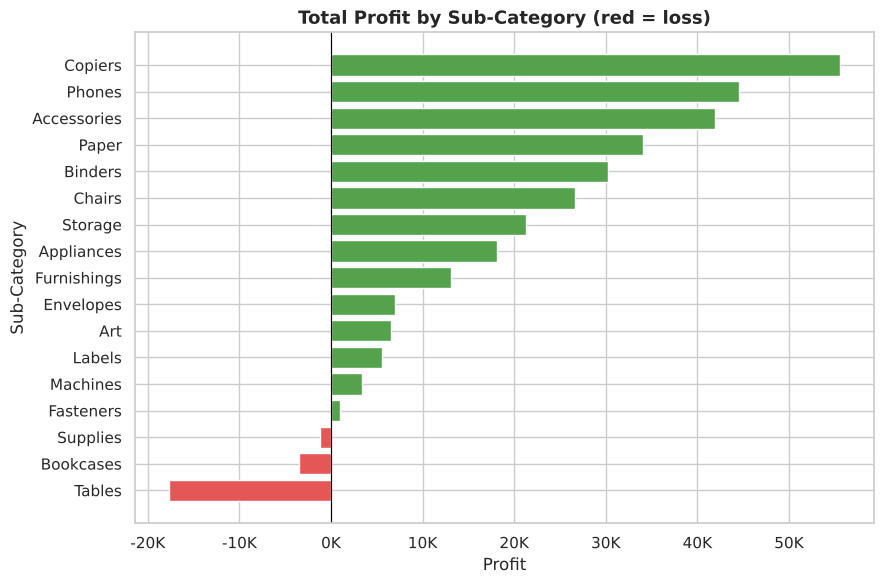

In [15]:
sub = df.groupby("Sub-Category")["Profit"].sum().sort_values()
print(sub.round(0).to_string())

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#E45756" if v < 0 else "#54A24B" for v in sub.values]
ax.barh(sub.index, sub.values, color=colors)
ax.axvline(0, color="black", lw=.8)
ax.set_title("Total Profit by Sub-Category (red = loss)")
ax.set_xlabel("Profit"); ax.set_ylabel("Sub-Category")
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1e3:,.0f}K")
save("04_profit_by_subcategory")
plt.show()

### Chart 5: Discount versus profit

            Profit  Avg_Margin  Lines
Discount                             
0.00      320987.6        34.0   4798
0.10        9029.2        15.6     94
0.15        1419.0         3.4     52
0.20       90337.3        17.7   3657
0.30      -10369.3       -11.5    227
0.32       -2391.1       -17.4     27
0.40      -23057.1       -22.2    206
0.45       -2493.1       -45.5     11
0.50      -20506.4       -54.9     66
0.60       -5944.7       -68.9    138
0.70      -40075.4       -79.5    418
0.80      -30539.0      -182.5    300


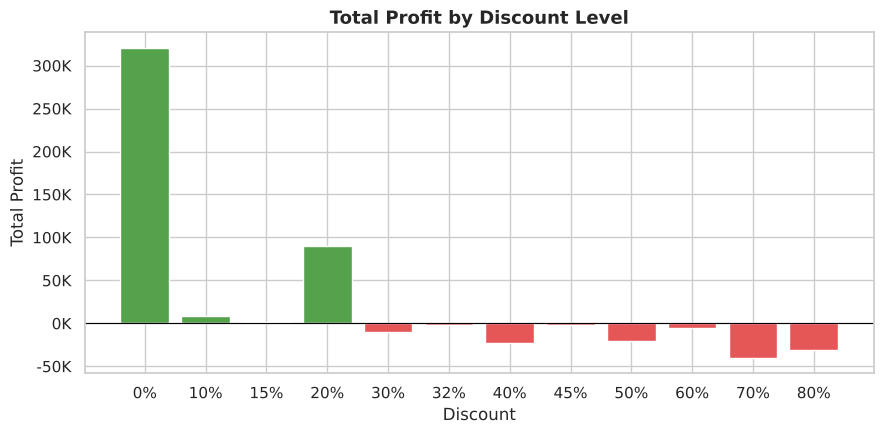

In [16]:
disc = df.groupby("Discount").agg(Profit=("Profit", "sum"), Avg_Margin=("Profit Margin %", "mean"), Lines=("Row ID", "count"))
print(disc.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#E45756" if v < 0 else "#54A24B" for v in disc["Profit"]]
ax.bar([f"{d:.0%}" for d in disc.index], disc["Profit"], color=colors)
ax.axhline(0, color="black", lw=.8)
ax.set_title("Total Profit by Discount Level")
ax.set_xlabel("Discount"); ax.set_ylabel("Total Profit")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1e3:,.0f}K")
save("07_profit_by_discount")
plt.show()

### Chart 6: Sales by customer segment

                 Sales    Profit
Segment                         
Consumer     1161401.0  134119.0
Corporate     706146.0   91979.0
Home Office   429653.0   60299.0


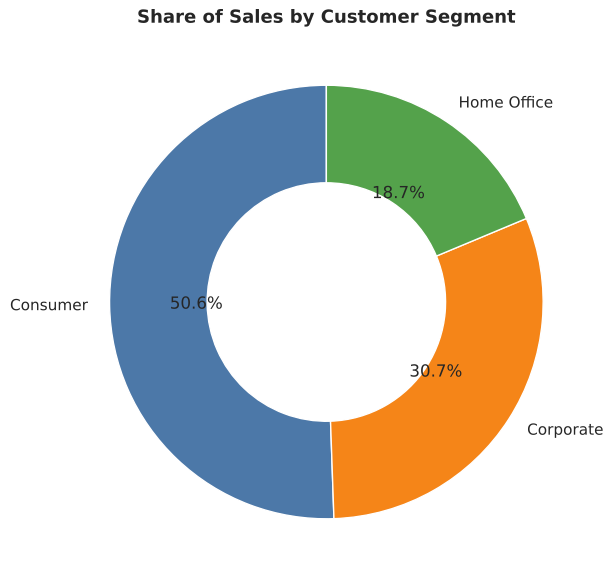

In [17]:
seg = df.groupby("Segment")[["Sales", "Profit"]].sum()
print(seg.round(0))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.pie(seg["Sales"], labels=seg.index, autopct="%1.1f%%", startangle=90,
       colors=["#4C78A8", "#F58518", "#54A24B"], wedgeprops={"width": .45, "edgecolor": "white"})
ax.set_title("Share of Sales by Customer Segment")
save("08_sales_by_segment")
plt.show()

### Chart 7: Top 10 products by sales

                                                      Sales   Profit
Product Name                                                        
High Speed Automatic Electric Letter Opener         17030.0   -262.0
GBC DocuBind P400 Electric Binding System           17965.0  -1878.0
HP Designjet T520 Inkjet Large Format Printer -...  18375.0   4095.0
Hewlett Packard LaserJet 3310 Copier                18840.0   6984.0
GBC Ibimaster 500 Manual ProClick Binding System    19024.0    761.0
GBC DocuBind TL300 Electric Binding System          19823.0   2234.0
HON 5400 Series Task Chairs for Big and Tall        21871.0      0.0
Cisco TelePresence System EX90 Videoconferencin...  22638.0  -1811.0
Fellowes PB500 Electric Punch Plastic Comb Bind...  27453.0   7753.0
Canon imageCLASS 2200 Advanced Copier               61600.0  25200.0


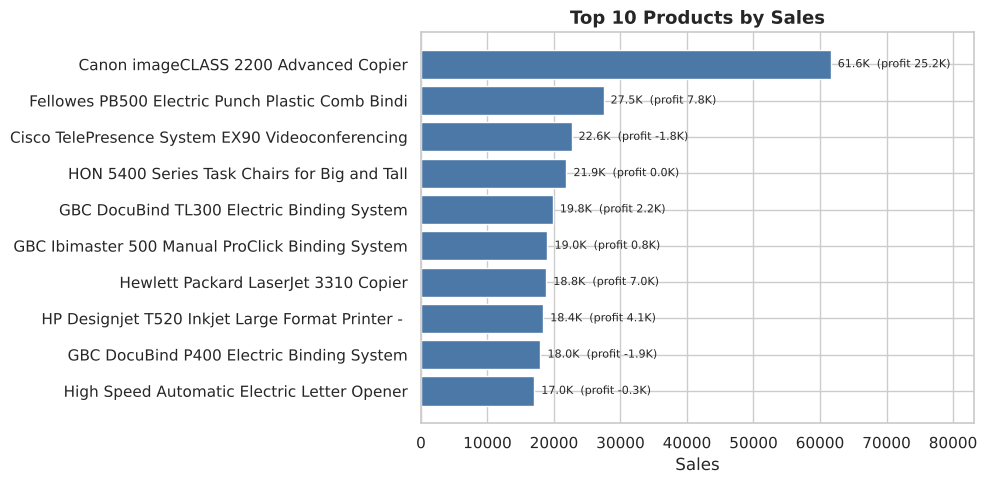

In [18]:
top = (df.groupby("Product Name")[["Sales", "Profit"]].sum().nlargest(10, "Sales").sort_values("Sales"))
print(top.round(0))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.index.str.slice(0, 48), top["Sales"], color="#4C78A8")
for i, (s, p) in enumerate(zip(top["Sales"], top["Profit"])):
    ax.text(s, i, f"  {s/1e3:,.1f}K  (profit {p/1e3:,.1f}K)", va="center", fontsize=8)
ax.set_xlim(0, top["Sales"].max() * 1.35)
ax.set_title("Top 10 Products by Sales"); ax.set_xlabel("Sales")
save("09_top10_products")
plt.show()

## 7. Key numbers for the insights

In [19]:
state = df.groupby("State")["Profit"].sum().sort_values()
print("Worst 5 states by profit:\n", state.head(5).round(0).to_string(), "\n")
print("Best 5 states by profit :\n", state.tail(5).round(0).to_string(), "\n")

sub_tbl = df.groupby("Sub-Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
sub_tbl["Margin %"] = sub_tbl["Profit"] / sub_tbl["Sales"] * 100
print(sub_tbl.sort_values("Margin %").round(1).to_string(), "\n")

high = df[df["Discount"] > 0.2]
print(f"Lines with discount > 20%: {len(high):,} ({len(high)/len(df):.1%}) | profit {high['Profit'].sum():,.0f}")
print(f"Lines with discount <= 20%: profit {df[df['Discount'] <= 0.2]['Profit'].sum():,.0f}")

best_month = df.groupby("Month Name")["Sales"].sum().sort_values(ascending=False)
print("\nTop 3 months (all years):", best_month.head(3).round(0).to_dict())
print("Avg delivery days by ship mode:\n", df.groupby("Ship Mode")["Delivery Days"].mean().round(1).to_string())

Worst 5 states by profit:
 State
Texas            -25729.0
Ohio             -16971.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0 

Best 5 states by profit :
 State
Virginia      18598.0
Michigan      24463.0
Washington    33403.0
New York      74039.0
California    76381.0 

                 Sales   Profit  Margin %
Sub-Category                             
Tables        206965.5 -17725.5      -8.6
Bookcases     114880.0  -3472.6      -3.0
Supplies       46673.5  -1189.1      -2.5
Machines      189238.6   3384.8       1.8
Chairs        328449.1  26590.2       8.1
Storage       223843.6  21278.8       9.5
Phones        330007.1  44515.7      13.5
Furnishings    91705.2  13059.1      14.2
Binders       203412.7  30221.8      14.9
Appliances    107532.2  18138.0      16.9
Art            27118.8   6527.8      24.1
Accessories   167380.3  41936.6      25.1
Fasteners       3024.3    949.5      31.4
Copiers       149528.0  55617.8      37.2
Envelopes      164

## 8. Business insights

See the README for the final list of 5 insights and 2 recommendations, which are based on the numbers above.